# Western blot validation - August 4, 2015
Plot the Western blot-derived phosphorylation levels for the proteins selected for validation with and without inhibitor treatments

In [370]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import os
import textwrap as tw
import scipy.stats as st

## Configure seaborn plotting defaults and set directories

In [337]:
sns.set() # Restore defaults
sns.set_palette('pastel')
# Enlarge the text labels
sns.set_context('paper', font_scale=1.75)
sns.set_style('whitegrid')

data_dir = os.path.join('..','..','validation')

## Create helper functions
* Prepare the condition names to be wrapped in axis labels
* Extract the treatment or control from the condition label
* Tweak the boxplot + stripplot legend
* Extract the EGF treatment time

In [186]:
def prep_wrap(df, col, width):
    # Use fill to wrap text into a single paragraph with newlines
    df[col] = df.apply(lambda row: tw.fill(row[col],width), axis=1)
    
def extract_treatment(condition):
    if 'nM' in condition: # Indicates drug treatment
        parts = condition.split(' ')
        return ' '.join(parts[1:])
    else:
        return 'No inhibitor'

# Seaborn doesn't allow fine grained control of legends, but matplotlib won't add legend text that starts with '_' to the legend.
# Create a new treatment column that starts with underscores that will not be added to the legend
def legend_trick(hue):
    return '_' + hue

def extract_time(condition):
    parts = condition.split("'") # ' indicates minutes
    return parts[0]    

## Use the t-test to calculate significance of changes at each time point
Use Welch's t-test (https://en.wikipedia.org/wiki/Welch%27s_t_test) because variance is unequal.  Two-sided test.  Use original phosphorylation levels (not relative).

In [417]:
def ttest(df, times, inh):
    for t in times:
        control_label = t + "'EGF"
        treatment_label = control_label + ' ' + inh
        control = df[df['condition'] == control_label]['phosphorylation']
        treatment = df[df['condition'] == treatment_label]['phosphorylation']
        (t, p) = st.ttest_ind(control, treatment, equal_var=False)
        print '%s vs %s: p = %f' % (control_label, treatment_label, p)

## Load the Zyxin, Crk, and Atp1a1 data

In [454]:
# Zyxin data
zyx_df = pd.read_csv(os.path.join(data_dir,'ValidationDataZyxin051215.txt'), sep='\t')
# Melt the data frame so that condition names are listed in a single column and the phosphorylation levels are given in another
zyx_df = pd.melt(zyx_df, id_vars='Zyxin pS 142/143', var_name='condition', value_name='phosphorylation')

# Split the condition label into the minutes of EGF treatment and the inhibitor applied
zyx_df['Time after EGF stimulation (min)'] = zyx_df.apply(lambda row: extract_time(row['condition']), axis=1)
zyx_df['Treatment'] = zyx_df.apply(lambda row: extract_treatment(row['condition']), axis=1)
zyx_df['Treatment no legend'] = zyx_df.apply(lambda row: legend_trick(row['Treatment']), axis=1)

# Plot relative phosphorylation
max_phos = zyx_df['phosphorylation'].max()
zyx_df['Relative phosphorylation'] = zyx_df.apply(lambda row: row['phosphorylation']/max_phos, axis=1)


# Crk data
crk_df = pd.read_csv(os.path.join(data_dir,'ValidationDataCrk051215.txt'), sep='\t')
# Melt the data frame so that condition names are listed in a single column and the phosphorylation levels are given in another
crk_df = pd.melt(crk_df, id_vars='CRKII pY 221', var_name='condition', value_name='phosphorylation')

# Split the condition label into the minutes of EGF treatment and the inhibitor applied
crk_df['Time after EGF stimulation (min)'] = crk_df.apply(lambda row: extract_time(row['condition']), axis=1)
crk_df['Treatment'] = crk_df.apply(lambda row: extract_treatment(row['condition']), axis=1)
crk_df['Treatment no legend'] = crk_df.apply(lambda row: legend_trick(row['Treatment']), axis=1)

# Plot relative phosphorylation
max_phos = crk_df['phosphorylation'].max()
crk_df['Relative phosphorylation'] = crk_df.apply(lambda row: row['phosphorylation']/max_phos, axis=1)


# Atp1a1 data
atp_df = pd.read_csv(os.path.join(data_dir,'ValidationDataAtp1a1051215.txt'), sep='\t')
# Melt the data frame so that condition names are listed in a single column and the phosphorylation levels are given in another
atp_df = pd.melt(atp_df, id_vars='ATP1A1 pY10', var_name='condition', value_name='phosphorylation')

# Split the condition label into the minutes of EGF treatment and the inhibitor applied
atp_df['Time after EGF stimulation (min)'] = atp_df.apply(lambda row: extract_time(row['condition']), axis=1)
atp_df['Treatment'] = atp_df.apply(lambda row: extract_treatment(row['condition']), axis=1)
atp_df['Treatment no legend'] = atp_df.apply(lambda row: legend_trick(row['Treatment']), axis=1)

# Plot relative phosphorylation
max_phos = atp_df['phosphorylation'].max()
atp_df['Relative phosphorylation'] = atp_df.apply(lambda row: row['phosphorylation']/max_phos, axis=1)

## Compute p-values in all three datasets to decide where to draw annotations

In [455]:
print 'Zyxin'
ttest(zyx_df, ['0', '4', '16'], '800nM MK-2206')

print '\nCrk'
ttest(crk_df, ['0', '4', '16'], '25nM Dasatinib')

print '\nAtp1a1'
ttest(atp_df, ['0', '8', '32'], '400nM SCH772984')

Zyxin
0'EGF vs 0'EGF 800nM MK-2206: p = 0.247218
4'EGF vs 4'EGF 800nM MK-2206: p = 0.032015
16'EGF vs 16'EGF 800nM MK-2206: p = 0.026362

Crk
0'EGF vs 0'EGF 25nM Dasatinib: p = 0.169453
4'EGF vs 4'EGF 25nM Dasatinib: p = 0.066351
16'EGF vs 16'EGF 25nM Dasatinib: p = 0.041010

Atp1a1
0'EGF vs 0'EGF 400nM SCH772984: p = 0.028350
8'EGF vs 8'EGF 400nM SCH772984: p = 0.031574
32'EGF vs 32'EGF 400nM SCH772984: p = 0.022048


## Plot the Zyxin relative phosphorylation levels in the six conditions
Whiskers show 1.5 * inter-quartile range (default per http://stanford.edu/~mwaskom/software/seaborn/generated/seaborn.boxplot.html#seaborn.boxplot)

Significance annotations from https://github.com/jbmouret/matplotlib_for_papers/blob/master/src/boxplot5.py

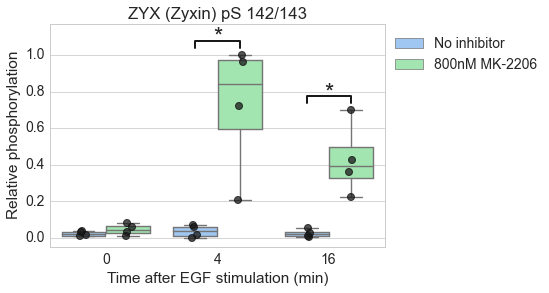

In [470]:
sns.boxplot(x='Time after EGF stimulation (min)', y='Relative phosphorylation', hue='Treatment', data=zyx_df)
# Use the 'no legend' version of the treatment, which begins with '_', so that the scatterplot will not be added to the legend
# Create a custom palette because the two graphs do not have the same hue
pal = {'_No inhibitor':'k', '_800nM MK-2206':'k'}
ax = sns.stripplot(x='Time after EGF stimulation (min)', y='Relative phosphorylation', hue='Treatment no legend', data=zyx_df, jitter=0.075, edgecolor='gray', palette = pal, alpha=0.75)

# Manually add anotations for statistical significance
# xy coords are the starting point of the arrow
# xytext are the ending point of the arrow
max_y = zyx_df[zyx_df['condition'] == "4'EGF 800nM MK-2206"]['Relative phosphorylation'].max()
ax.annotate('', xy=(0.8, max_y + 0.03), xycoords='data',
            xytext=(1.2, max_y + 0.03), textcoords='data',
            arrowprops=dict(arrowstyle='-', facecolor='k', linewidth=2, connectionstyle='bar,fraction=0.2'))
# First coord gives the 0-based index of which condition the annotation is for
# Second coord gives the y value in terms of the data's y values
ax.text(1, max_y + 0.06, '*', fontsize=24, horizontalalignment='center')

max_y = zyx_df[zyx_df['condition'] == "16'EGF 800nM MK-2206"]['Relative phosphorylation'].max()
ax.annotate('', xy=(1.8, max_y + 0.03), xycoords='data',
            xytext=(2.2, max_y + 0.03), textcoords='data',
            arrowprops=dict(arrowstyle='-', facecolor='k', linewidth=2, connectionstyle='bar,fraction=0.2'))
ax.text(2, max_y + 0.06, '*', fontsize=24, horizontalalignment='center')

# Disable the legend title
lgd = ax.legend()
lgd.set_title('')
# Move the legend
lgd.set_bbox_to_anchor((1.49,1))

ax.set_title('ZYX (Zyxin) pS 142/143')
ax.set_ylim(-0.05, 1.17)

# Save the figure as .png and .svg
#plt.tight_layout()
# Include the legend in the saved image http://stackoverflow.com/questions/10101700/moving-matplotlib-legend-outside-of-the-axis-makes-it-cutoff-by-the-figure-box
plt.savefig(os.path.join(data_dir, 'zyxin-western-080415.png'), dpi=600, bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.savefig(os.path.join(data_dir, 'zyxin-western-080415.svg'), bbox_extra_artists=(lgd,), bbox_inches='tight')

## Plot the Crk relative phosphorylation levels in the six conditions

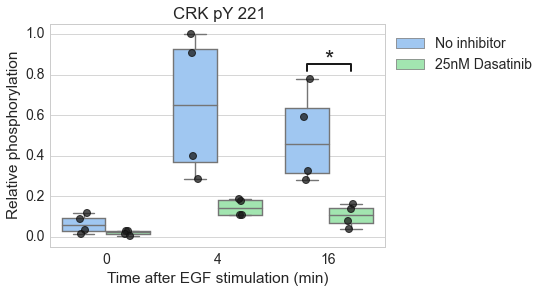

In [476]:
sns.boxplot(x='Time after EGF stimulation (min)', y='Relative phosphorylation', hue='Treatment', data=crk_df)
# Use the 'no legend' version of the treatment, which begins with '_', so that the scatterplot will not be added to the legend
# Create a custom palette because the two graphs do not have the same hue
pal = {'_No inhibitor':'k', '_25nM Dasatinib':'k'}
ax = sns.stripplot(x='Time after EGF stimulation (min)', y='Relative phosphorylation', hue='Treatment no legend', data=crk_df, jitter=0.075, edgecolor='gray', palette = pal, alpha=0.75)

# Manually add anotations for statistical significance
max_y = crk_df[crk_df['condition'] == "16'EGF"]['Relative phosphorylation'].max()
ax.annotate('', xy=(1.8, max_y + 0.03), xycoords='data',
            xytext=(2.2, max_y + 0.03), textcoords='data',
            arrowprops=dict(arrowstyle='-', facecolor='k', linewidth=2, connectionstyle='bar,fraction=0.2'))
ax.text(2, max_y + 0.06, '*', fontsize=24, horizontalalignment='center')

# Disable the legend title
lgd = ax.legend()
lgd.set_title('')
# Move the legend
lgd.set_bbox_to_anchor((1.475,1))

# Crk or CrkII?
ax.set_title('CRK pY 221')
ax.set_ylim(-0.05, 1.05)

# Save the figure as .png and .svg
#plt.tight_layout()
# Include the legend in the saved image http://stackoverflow.com/questions/10101700/moving-matplotlib-legend-outside-of-the-axis-makes-it-cutoff-by-the-figure-box
plt.savefig(os.path.join(data_dir, 'crk-western-080415.png'), dpi=600, bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.savefig(os.path.join(data_dir, 'crk-western-080415.svg'), bbox_extra_artists=(lgd,), bbox_inches='tight')

## Plot the Atp1a1 relative phosphorylation levels in the six conditions

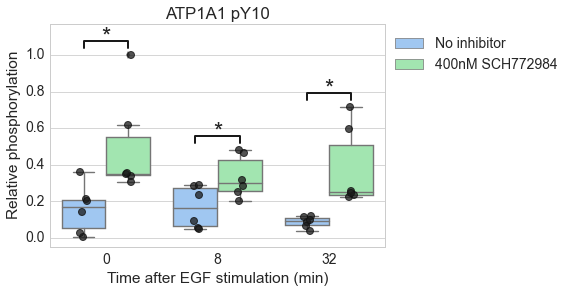

In [472]:
sns.boxplot(x='Time after EGF stimulation (min)', y='Relative phosphorylation', hue='Treatment', data=atp_df)
# Use the 'no legend' version of the treatment, which begins with '_', so that the scatterplot will not be added to the legend
# Create a custom palette because the two graphs do not have the same hue
pal = {'_No inhibitor':'k', '_400nM SCH772984':'k'}
ax = sns.stripplot(x='Time after EGF stimulation (min)', y='Relative phosphorylation', hue='Treatment no legend', data=atp_df, jitter=0.075, edgecolor='gray', palette = pal, alpha=0.75)

# Manually add anotations for statistical significance
# xy coords are the starting point of the arrow
# xytext are the ending point of the arrow
max_y = atp_df[atp_df['condition'] == "0'EGF 400nM SCH772984"]['Relative phosphorylation'].max()
ax.annotate('', xy=(-0.2, max_y + 0.03), xycoords='data',
            xytext=(0.2, max_y + 0.03), textcoords='data',
            arrowprops=dict(arrowstyle='-', facecolor='k', linewidth=2, connectionstyle='bar,fraction=0.2'))
# First coord gives the 0-based index of which condition the annotation is for
# Second coord gives the y value in terms of the data's y values
ax.text(0, max_y + 0.06, '*', fontsize=24, horizontalalignment='center')

max_y = atp_df[atp_df['condition'] == "8'EGF 400nM SCH772984"]['Relative phosphorylation'].max()
ax.annotate('', xy=(0.8, max_y + 0.03), xycoords='data',
            xytext=(1.2, max_y + 0.03), textcoords='data',
            arrowprops=dict(arrowstyle='-', facecolor='k', linewidth=2, connectionstyle='bar,fraction=0.2'))
ax.text(1, max_y + 0.06, '*', fontsize=24, horizontalalignment='center')

max_y = atp_df[atp_df['condition'] == "32'EGF 400nM SCH772984"]['Relative phosphorylation'].max()
ax.annotate('', xy=(1.8, max_y + 0.03), xycoords='data',
            xytext=(2.2, max_y + 0.03), textcoords='data',
            arrowprops=dict(arrowstyle='-', facecolor='k', linewidth=2, connectionstyle='bar,fraction=0.2'))
ax.text(2, max_y + 0.06, '*', fontsize=24, horizontalalignment='center')

# Disable the legend title
lgd = ax.legend()
lgd.set_title('')
# Move the legend
lgd.set_bbox_to_anchor((1.55,1))

ax.set_title('ATP1A1 pY10')
ax.set_ylim(-0.05, 1.17)

# Save the figure as .png and .svg
#plt.tight_layout()
# Include the legend in the saved image http://stackoverflow.com/questions/10101700/moving-matplotlib-legend-outside-of-the-axis-makes-it-cutoff-by-the-figure-box
plt.savefig(os.path.join(data_dir, 'atp1a1-western-080415.png'), dpi=600, bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.savefig(os.path.join(data_dir, 'atp1a1-western-080415.svg'), bbox_extra_artists=(lgd,), bbox_inches='tight')

## Alternative plotting style that plots each condition individually

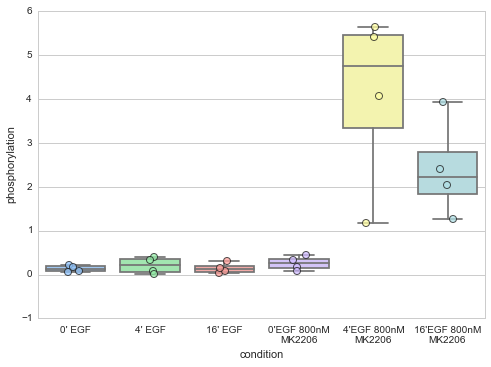

In [223]:
# Add newlines to the condition labels.  Only needed if plotting each condition as a separate bar
prep_wrap(zyx_df, 'condition', 15)

sns.boxplot(x='condition', y='phosphorylation', data=zyx_df, palette='pastel')
sns.stripplot(x='condition', y='phosphorylation', data=zyx_df, jitter=True, edgecolor='k', palette='pastel', alpha=0.75)